In [5]:
import numpy as np
import matplotlib.pyplot as plt

def compute_cost(X, y, theta, lambda_):
    """
    Compute the cost function for regularized linear regression.
    """
    m = len(y)
    predictions = X @ theta
    error = predictions - y
    cost = (1 / (2 * m)) * np.sum(np.square(error))
    regularization = (lambda_ / (2 * m)) * np.sum(np.square(theta[1:]))
    return cost + regularization

def gradient_descent(X, y, theta, alpha, num_iters, lambda_):
    """
    Perform gradient descent to learn theta.
    
    Parameters:
    X : numpy array, shape (m, n+1)
        Feature matrix with intercept term.
    y : numpy array, shape (m,)
        Target values.
    theta : numpy array, shape (n+1,)
        Initial parameters.
    alpha : float
        Learning rate.
    num_iters : int
        Number of iterations.
    lambda_ : float
        Regularization parameter.

    Returns:
    theta : numpy array, shape (n+1,)
        Optimized parameters.
    J_history : list
        History of cost values during optimization.
    """
    m = len(y)
    J_history = []
    
    for _ in range(num_iters):
        # Compute the predictions and errors
        predictions = X @ theta
        error = predictions - y
        
        # Update the parameters with regularization
        gradient = (1 / m) * (X.T @ error) + (lambda_ / m) * np.r_[[0], theta[1:]]
        theta -= alpha * gradient
        
        # Compute and record the cost
        cost = compute_cost(X, y, theta, lambda_)
        J_history.append(cost)
    
    return theta, J_history




In [6]:
# Example usage
X = np.array([[1, 2], [1, 3], [1, 4]])  # Feature matrix with intercept term
y = np.array([1, 2, 3])  # Target values
theta = np.array([0.5, 0.5])  # Initial parameters
alpha = 0.01  # Learning rate
num_iters = 1000  # Number of iterations
lambda_ = 1  # Regularization parameter

# Run gradient descent
theta, J_history = gradient_descent(X, y, theta, alpha, num_iters, lambda_)

print(f'Optimized Theta: {theta}')
print(f'Final Cost: {J_history[-1]}')

Optimized Theta: [0.20152153 0.60565086]
Final Cost: 0.11314322190543052


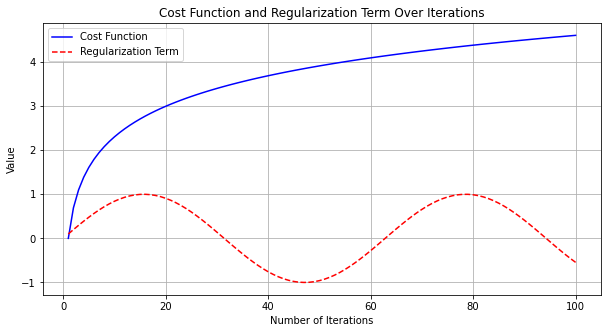

In [8]:
iterations = np.arange(1, 101)  # Number of iterations
costs = np.log(iterations)  # Dummy cost values for illustration
regularization_terms = np.sin(iterations / 10)  # Dummy regularization terms
# Create a figure and axis
plt.figure(figsize=(10, 5))

# Plot cost over iterations
plt.plot(iterations, costs, label='Cost Function', color='blue')

# If you want to include regularization term plots
plt.plot(iterations, regularization_terms, label='Regularization Term', color='red', linestyle='--')

# Add titles and labels
plt.title('Cost Function and Regularization Term Over Iterations')
plt.xlabel('Number of Iterations')
plt.ylabel('Value')
plt.legend()

# Show the plot
plt.grid(True)
plt.show()